# 00 · Data pipeline: check the training dataset

**What this notebook does.** It opens the dataset we train the animal detector on and checks it, step by step:

1. the class ids and where each class came from,
2. the YOLO label format and a validation pass,
3. a visual spot-check (boxes drawn on random training images),
4. the group split (images from one video or source never sit in two splits),
5. box counts per class and per split,
6. an overview of the sources.

**How to run.** Run the cells top to bottom (Run all). Nothing here trains a model, and nothing here changes the data.

**Quick or full.** The default is *quick*: the checks read 10 images per split. Set `FULL_RUN = True` in the parameters cell to check every image (about a minute on this machine). The spot-check and the group split are the same in both modes.

In [1]:
from pathlib import Path
import os

# Find the project root (the folder that holds PROJECT_PLAN.md) and work from there,
# so every path in this notebook is relative to the project root.
root = Path.cwd().resolve()
while not (root / "PROJECT_PLAN.md").exists():
    if root.parent == root:
        raise SystemExit("PROJECT_PLAN.md not found above this folder")
    root = root.parent
os.chdir(root)
print("project root:", root)

# Only for the offline runner in notebooks/run_notebook.py, whose IPython stand-in lacks these
# two attributes. Real Jupyter has them, so this block does nothing there.
import IPython
if not hasattr(IPython, "get_ipython"):
    IPython.get_ipython = lambda: None
    IPython.version_info = (8, 24, 0)
import warnings
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive")

project root: /home/upicy/comp_vision


## Parameters

Change these values here only. Every other cell reads them.

In [2]:
FULL_RUN = False        # False = quick: check 10 images per split. True = check every image.
SAMPLE_N = 10           # images per split used when FULL_RUN is False
SPOT_CHECK_N = 12       # random training images drawn with their boxes
SEED = 1                # same seed = same random picks every run

DATASET = Path("data/dataset")          # the v2 dataset (see data/SOURCES.md)
SPLITS = ["train", "val", "test", "test_extra"]
CLASS_NAMES = ["dog", "goat", "cow", "cat", "sheep"]
IMG_EXTS = {".jpg", ".jpeg", ".png"}

print("mode:", "FULL" if FULL_RUN else f"quick ({SAMPLE_N} images per split)")
print("dataset folder:", DATASET.resolve())

mode: quick (10 images per split)
dataset folder: /home/upicy/comp_vision/data/dataset


## 1. Class ids and where each class comes from

The model learns five classes. The id number is what goes into every label file, so it must never change.
Each source has its own class names, so every source is mapped to our ids before it goes in (see `data/label_map.md`).

In [3]:
import pandas as pd
from IPython.display import display

label_map = pd.DataFrame({
    "id": range(len(CLASS_NAMES)),
    "name": CLASS_NAMES,
    "main sources": [
        "Open Images Dog; stray-dog Roboflow sets (not downloaded yet)",
        "Open Images Goat; Mendeley herbivores5 Goat (its id 3)",
        "Open Images Cattle; Mendeley Buffalo (id 0) and Cow (id 2)",
        "Open Images Cat",
        "Open Images goat/sheep set; Mendeley herbivores5 Sheep (id 4)",
    ],
})
display(label_map)

,id,name,main sources
0,0,dog,Open Images Dog; stray-dog Roboflow sets (not downloaded yet)
1,1,goat,Open Images Goat; Mendeley herbivores5 Goat (its id 3)
2,2,cow,Open Images Cattle; Mendeley Buffalo (id 0) and Cow (id 2)
3,3,cat,Open Images Cat
4,4,sheep,Open Images goat/sheep set; Mendeley herbivores5 Sheep (id 4)


## 2. The label format and a validation pass

Each image has a text file with the same name. Every line in it is one box:

`class x_centre y_centre width height`

All numbers after the class are between 0 and 1, and they are fractions of the image width and height.
The check below looks for the usual mistakes: wrong number of fields, a class id outside 0 to 4, a box outside the image,
a zero-size box, an image with no label file, and an unreadable image.
An empty label file is allowed; it means the picture has no animal in it.

In [4]:
import collections
from PIL import Image

problems = []
images_checked = collections.Counter()
boxes_checked = 0

for split in SPLITS:
    images = sorted(p for p in (DATASET / "images" / split).iterdir() if p.suffix.lower() in IMG_EXTS)
    if not FULL_RUN:
        images = images[:SAMPLE_N]
    for img in images:
        images_checked[split] += 1
        label = DATASET / "labels" / split / (img.stem + ".txt")
        if not label.exists():
            problems.append(f"{split}/{img.name}: no label file")
            continue
        try:
            Image.open(img).close()        # raises if the file is corrupt
        except Exception as exc:
            problems.append(f"{split}/{img.name}: cannot open image ({exc})")
            continue
        for n, line in enumerate(label.read_text().splitlines(), 1):
            if not line.strip():
                continue
            parts = line.split()
            where = f"{label}:{n}"
            if len(parts) != 5:
                problems.append(f"{where}: expected 5 numbers, got {len(parts)}")
                continue
            try:
                cls = int(parts[0])
                x, y, w, h = (float(v) for v in parts[1:])
            except ValueError:
                problems.append(f"{where}: not a number in '{line.strip()}'")
                continue
            if not 0 <= cls < len(CLASS_NAMES):
                problems.append(f"{where}: class id {cls} is not in 0..4")
            elif not all(0 <= v <= 1 for v in (x, y, w, h)):
                problems.append(f"{where}: a value is outside 0..1")
            elif w <= 0 or h <= 0:
                problems.append(f"{where}: width and height must be above 0")
            else:
                boxes_checked += 1

display(pd.DataFrame({"split": list(images_checked), "images checked": list(images_checked.values())}))
print("boxes checked:", boxes_checked)
print("problems found:", len(problems))
for p in problems[:20]:
    print("  ", p)
if not problems:
    print("PASS: every checked image and label is valid")

boxes checked: 66
problems found: 0
PASS: every checked image and label is valid


,split,images checked
0,train,10
1,val,10
2,test,10
3,test_extra,10


## 3. Spot-check: draw the boxes on random training images

A number check cannot tell you a box sits on the wrong animal. Look at these pictures by eye.
Colours: dog red, goat blue, cow lime, cat orange, sheep magenta. Any box in the wrong place, or an animal with no box, is a problem to report.
This check always uses the same random picks for a given seed, whatever `FULL_RUN` is.

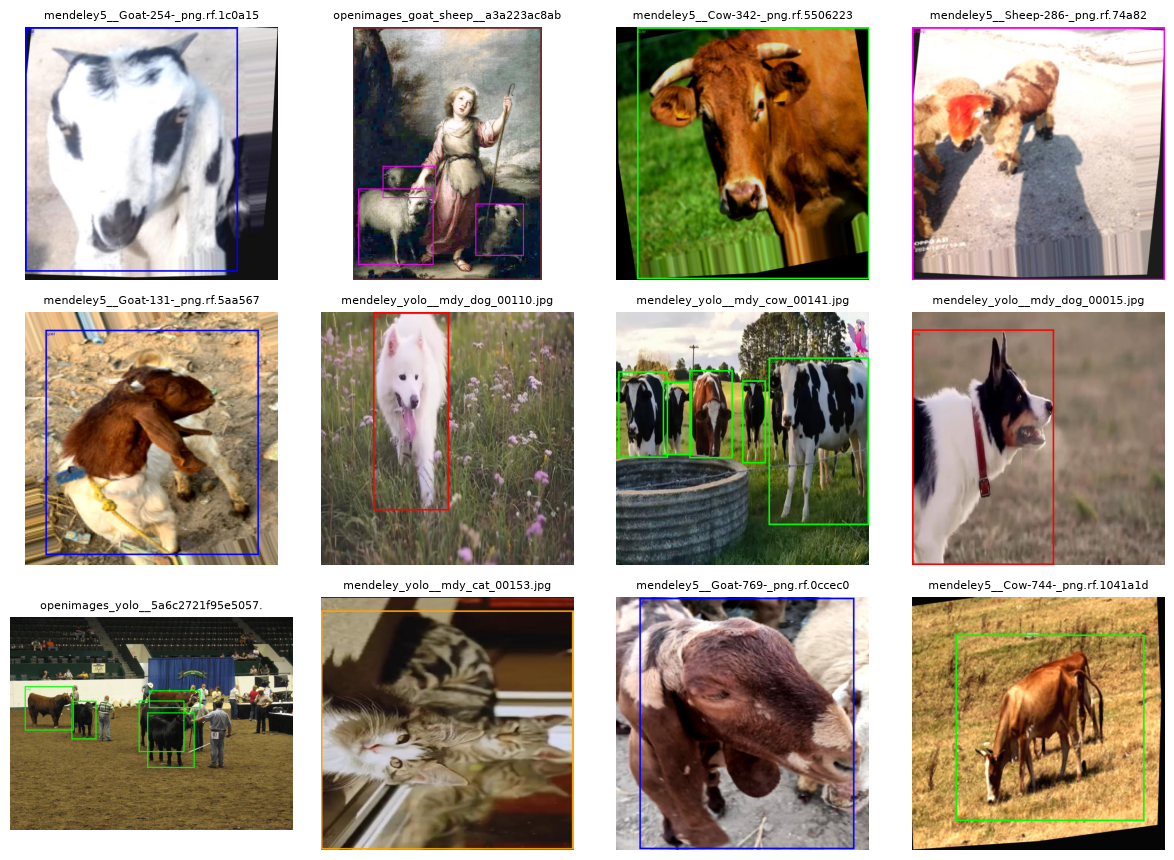

In [5]:
import random
import matplotlib.pyplot as plt
from PIL import ImageDraw

COLORS = ["red", "blue", "lime", "orange", "magenta"]
rng = random.Random(SEED)
train_images = sorted((DATASET / "images" / "train").glob("*.jpg"))
picks = rng.sample(train_images, SPOT_CHECK_N)

cols = 4
rows = (len(picks) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(12, 2.9 * rows))
for ax, img_path in zip(axes.flat, picks):
    im = Image.open(img_path).convert("RGB")
    W, H = im.size
    draw = ImageDraw.Draw(im)
    label = DATASET / "labels" / "train" / (img_path.stem + ".txt")
    for line in label.read_text().splitlines():
        if not line.strip():
            continue
        c, xc, yc, w, h = line.split()
        c = int(c)
        x1, y1 = (float(xc) - float(w) / 2) * W, (float(yc) - float(h) / 2) * H
        x2, y2 = (float(xc) + float(w) / 2) * W, (float(yc) + float(h) / 2) * H
        draw.rectangle([x1, y1, x2, y2], outline=COLORS[c], width=4)
        draw.text((x1 + 4, y1 + 4), CLASS_NAMES[c], fill=COLORS[c])
    ax.imshow(im)
    ax.set_title(img_path.name[:34], fontsize=8)
    ax.axis("off")
for ax in list(axes.flat)[len(picks):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. The group split: why images are not split one by one

Video frames and near-copies look almost the same. If one frame is in training and its neighbour is in test, the test score is inflated.
So each image belongs to a **group** (one video, or one source image), and a whole group goes to one split.
The split is 70 % train, 20 % val, 10 % test, by image count.

The manifest `split_manifest.csv` records the group and split of every image. The check below counts images and groups per split,
and looks for any group that appears in two splits. The expected answer is zero.

In [6]:
manifest = pd.read_csv(DATASET / "split_manifest.csv")
manifest["source"] = manifest["file"].str.split("__").str[0]

per_split = manifest.groupby("split").agg(images=("file", "size"), groups=("group", "nunique"))
display(per_split)

in_two_splits = manifest.groupby("group")["split"].nunique()
print("groups that appear in more than one split:", int((in_two_splits > 1).sum()), "(must be 0)")

groups that appear in more than one split: 0 (must be 0)


,images,groups
split,,
test,80,80
test_extra,80,80
train,2993,2993
val,634,634


### How a group is given to a split (a toy example)

The function below is the same idea as `assign_splits` in `src/data/split_dataset.py`, run on six made-up groups.
It hands out the biggest groups first, to whichever split is furthest below its target.

In [7]:
import random

def assign_splits(groups, ratios, seed):
    rng = random.Random(seed)
    keys = list(groups)
    rng.shuffle(keys)
    total = sum(len(groups[k]) for k in keys)
    target = {s: ratios[s] * total for s in ratios}
    current = {s: 0 for s in ratios}
    result = {}
    for key in sorted(keys, key=lambda k: -len(groups[k])):
        split = max(ratios, key=lambda s: target[s] - current[s])
        result[key] = split
        current[split] += len(groups[key])
    return result

toy_groups = {"clip_A": list("abcd"), "clip_B": ["b1"], "clip_C": ["c1", "c2"],
              "clip_D": ["d1", "d2", "d3"], "clip_E": ["e1"], "clip_F": ["f1", "f2"]}
toy_split = assign_splits(toy_groups, {"train": 0.7, "val": 0.2, "test": 0.1}, SEED)
display(pd.DataFrame([{"group": g, "images": len(f), "split": toy_split[g]} for g, f in toy_groups.items()]))

,group,images,split
0,clip_A,4,train
1,clip_B,1,val
2,clip_C,2,val
3,clip_D,3,train
4,clip_E,1,test
5,clip_F,2,train


## 5. Box counts per class and per split

Each row is a split and each column is a class. Quick mode counts only the first 10 label files per split,
so use `FULL_RUN = True` for the real numbers. Counting reads label text files only, so it is quick either way.

class,dog,goat,cow,cat,sheep,total
split,,,,,,
train,0,0,10,0,0,10
val,0,0,10,0,0,10
test,2,6,14,0,0,22
test_extra,0,9,0,0,15,24


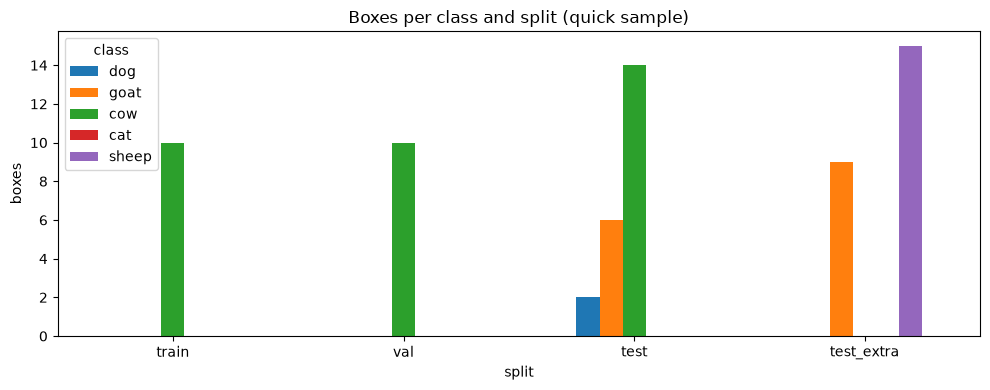

In [8]:
import matplotlib.pyplot as plt

rows = []
for split in SPLITS:
    labels = sorted((DATASET / "labels" / split).glob("*.txt"))
    if not FULL_RUN:
        labels = labels[:SAMPLE_N]
    for lp in labels:
        for line in lp.read_text().splitlines():
            if line.strip():
                rows.append((split, CLASS_NAMES[int(line.split()[0])]))

counts = pd.crosstab(pd.Series([s for s, _ in rows], name="split"),
                     pd.Series([c for _, c in rows], name="class"))
counts = counts.reindex(index=SPLITS, columns=CLASS_NAMES, fill_value=0)
counts["total"] = counts.sum(axis=1)
display(counts)

ax = counts[CLASS_NAMES].plot.bar(figsize=(10, 4), rot=0)
ax.set_ylabel("boxes")
ax.set_title("Boxes per class and split (" + ("full dataset" if FULL_RUN else "quick sample") + ")")
ax.legend(title="class")
plt.tight_layout()
plt.show()

## 6. Sources overview

Each image name starts with its source (the part before the first `__`). The table counts images per source and split.
Licences are in `data/SOURCES.md`; the short version is below.

| Source | Images from | Licence (see `data/SOURCES.md`) |
|---|---|---|
| Open Images (boxes and images) | Google Open Images V7 | annotations CC BY 4.0; images CC BY 2.0 (per image) |
| Mendeley herbivores5 | Mendeley Data | CC BY 4.0 |
| Mendeley street animals (`mendeley_yolo`) | Mendeley street-animal photos; **boxes made by our own detector**, not by people | not stated in `data/SOURCES.md`; check the dataset page before release |

Roboflow Universe sets are **not** in this dataset yet: each needs a manual download (their pages return 403 to scripts).

In [9]:
by_source = manifest.groupby(["source", "split"]).size().unstack(fill_value=0)
by_source["total"] = by_source.sum(axis=1)
display(by_source)

split,test,test_extra,train,val,total
source,,,,,
mendeley5,0,0,1402,395,1797
mendeley_yolo,0,0,689,0,689
openimages_goat_sheep,0,80,344,79,503
openimages_yolo,80,0,558,160,798


## Next

Notebook 05 shows how the web app uses the trained model. Run order is in `notebooks/README.md`.